In [217]:
# Standard imports
import numpy as np
import scipy
import matplotlib.pyplot as plt

import pickle
import os
from copy import deepcopy

import at

import utils as u

from importlib import reload
reload(u.plot);
reload(u.at);

In [218]:
with open('candidates/v01_03_01_01/ring.pkl', 'rb') as file:
    ring = pickle.load(file)

with open('candidates/n01_02_01_01/ring.pkl', 'rb') as file:
    TDR_1 = pickle.load(file)

## Using Wiedemann

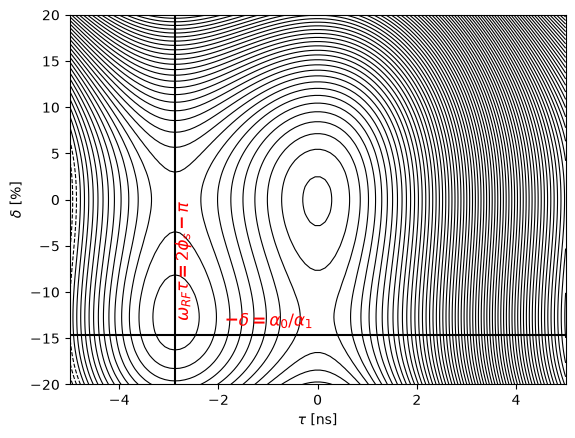

In [219]:
def plot_longitudinal(mcf, E0=3e9, V0=1.2e6, f_rf=100e6):
    T0 = 32 / f_rf 
    phi_s = np.arcsin(ring.energy_loss / V0)

    def H(phi, delta):
        return (
            2*np.pi*f_rf * sum([mcf[i]*delta**(i+2)/(i+2) for i in range(len(mcf))])
            - V0/(E0*T0) * (np.cos(phi+phi_s) - 1 + (phi)*np.sin(phi_s))
        )

    N = 100
    phi_range = np.linspace(-np.pi, np.pi, N)
    delta_range = np.linspace(-0.2, 0.2, N)

    phi, delta = np.meshgrid(phi_range, delta_range)
    tau = -phi/(2*np.pi*f_rf)

    plt.contour(
        1e9*tau, 1e2*delta, H(phi, delta), levels=100, colors='black', linewidths=0.8
    )

    if len(mcf >= 2):
        tau_a = (2*phi_s-np.pi)/(2*np.pi*f_rf)
        delta_a = -mcf[0]/mcf[1]
        
        if delta.min() < delta_a < delta.max():
            plt.axvline(1e9*tau_a, c='black')
            plt.axhline(1e2*delta_a, c='black')

            plt.text(1e9*tau_a+1, 1e2*delta_a+1, r'$-\delta = \alpha_0 / \alpha_1$', c='red', size=12)
            plt.text(1e9*tau_a, 1e2*delta_a+2, r'$\omega_{RF}\tau = 2\phi_s-\pi$', c='red', size=12, rotation=90)

    plt.xlabel(r'$\tau$ [ns]')
    plt.ylabel(r'$\delta$ [%]')
    plt.xlim(1e9*tau.min(), 1e9*tau.max())
    plt.ylim(1e2*delta.min(), 1e2*delta.max())
    plt.show()

mcf = TDR_1.get_mcf(fit_order=3, n_step=51)
mcf[1] *= 1
mcf[2] *= 1
plot_longitudinal(mcf, V0=0.84e6)

## Tune higher order momentum compaction factors


1 constraints, 4 variables, using method trf

`xtol` termination condition is satisfied.
Function evaluations 47, initial cost 1.8952e+04, final cost 2.1292e-12, first-order optimality 1.87e-06.

Constraints:

    location              Initial            Actual         Low bound        High bound         deviation 
alpha_1
                          389.375           194.688           194.688           194.688      -8.36143e-06 

Variables:

        Name      Initial          Final        Variation

       S1_v1   -1.149110e+02   -1.132816e+02    1.629354e+00
       S2_v1    2.375010e+02    3.293680e+02    9.186696e+01
       S3_v1   -3.021005e+02   -2.494727e+02    5.262780e+01
       S4_v1    3.283771e+02    4.665715e+02    1.381944e+02
Final values
[ 4.02158620e-05  1.94687645e-04 -1.02113458e-04]


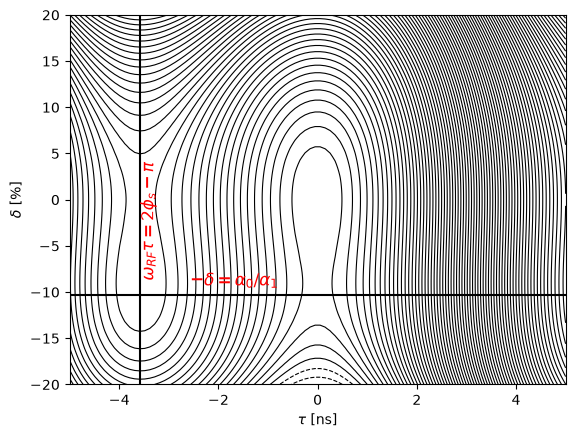

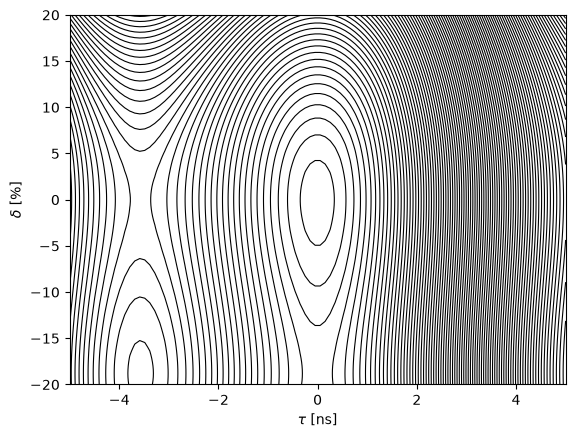

In [236]:
ring_opt = deepcopy(ring)

vars = at.VariableList([
    at.ElementVariable(ring_opt['S1_v1'], 'PolynomB', index=2, name='S1_v1'),
    at.ElementVariable(ring_opt['S2_v1'], 'PolynomB', index=2, name='S2_v1'),
    at.ElementVariable(ring_opt['S3_v1'], 'PolynomB', index=2, name='S3_v1'),
    at.ElementVariable(ring_opt['S4_v1'], 'PolynomB', index=2, name='S4_v1'),
])

def get_alpha_0(ring):
    return 1e6*ring.get_mcf()

def get_alpha_1(ring):
    return 1e6*ring.get_mcf(fit_order=2, n_step=5)[1]

def get_alpha_2(ring):
    return 1e6*ring.get_mcf(fit_order=3, n_step=9)[2]

target_mcf = 1e6*ring.get_mcf(fit_order=3, n_step=9)
target_mcf[1] *= 0.5
target_mcf[2] *= 1
obs = at.ObservableList([
    # at.RingObservable(get_alpha_0, 'alpha_0', target=target_mcf[0]),
    at.RingObservable(get_alpha_1, 'alpha_1', target=target_mcf[1]),
    # at.RingObservable(get_alpha_2, 'alpha_2', target=target_mcf[2]),
])

ring_opt.match(vars, obs, verbose=1)

print('Final values')
print(ring_opt.get_mcf(fit_order=3, n_step=9))

plot_longitudinal(ring.get_mcf(fit_order=3, n_step=9))
plot_longitudinal(ring_opt.get_mcf(fit_order=3, n_step=9))